In [ ]:
import os
import seaborn as sns

# Attention, modifiez le chemin vers votre dossier contenant le notebook et les fichiers csv !
os.chdir(r".....")

# Pour vérifier
print("Nouveau répertoire :", os.getcwd())

In [2]:
import pandas as pd
try:
    customers = pd.read_csv('customers.csv')
    Transactions = pd.read_csv('Transactions.csv')
    products = pd.read_csv('products.csv')
    
    print("✅ Les fichiers ont bien été chargés.")
except Exception as e:
    print("❌ Erreur lors du chargement :", e)

✅ Les fichiers ont bien été chargés.


Avant de faire les jointures, on va vérifier qu'il n y a pas d'éléments aberrants dans les fichiers :

Customers :

In [5]:
customers.head(10)


,client_id,sex,birth
0,c_4410,f,1967
1,c_7839,f,1975
2,c_1699,f,1984
3,c_5961,f,1962
4,c_5320,m,1943
5,c_415,m,1993
6,c_285,f,1967
7,c_160,f,1978
8,c_6446,m,1971
9,c_6866,m,1993


In [6]:
customers.shape

(8621, 3)

In [7]:
customers["client_id"].nunique()

8621

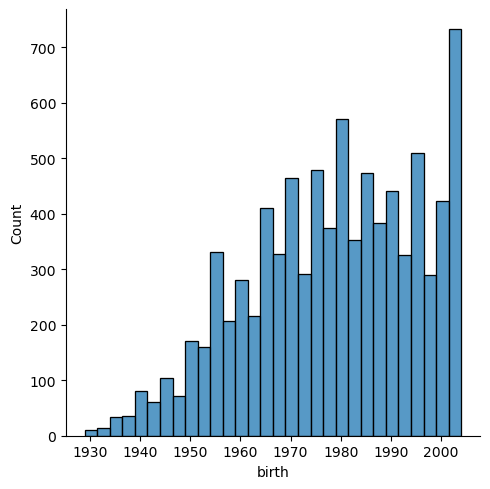

In [8]:
sns.displot(customers, x="birth")

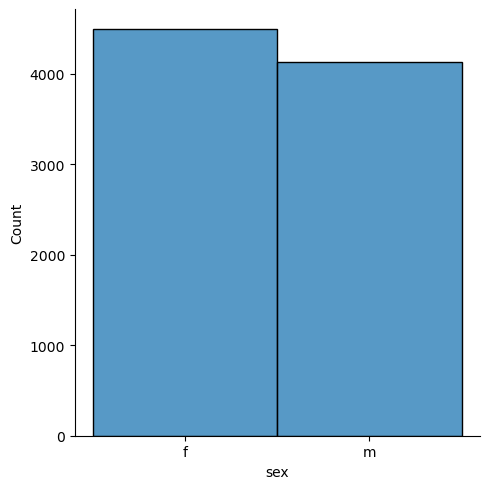

In [9]:
sns.displot(customers, x="sex")

Products : 

In [11]:
products.head(10)

,id_prod,price,categ
0,0_1421,19.99,0
1,0_1368,5.13,0
2,0_731,17.99,0
3,1_587,4.99,1
4,0_1507,3.99,0
5,0_1163,9.99,0
6,1_463,36.99,1
7,0_2157,34.99,0
8,0_1915,16.99,0
9,0_389,18.99,0


In [12]:
products.shape

(3286, 3)

In [13]:
products["id_prod"].nunique()

3286

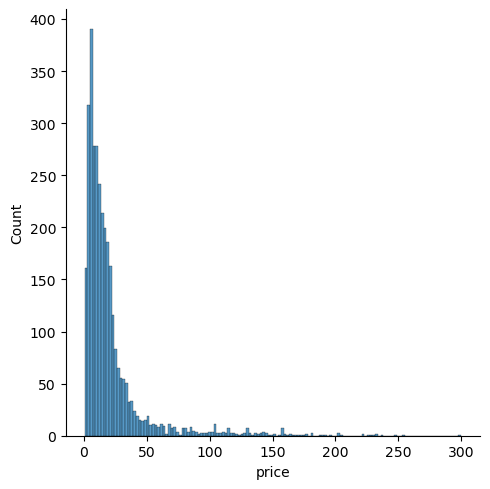

In [14]:
sns.displot(products, x='price')

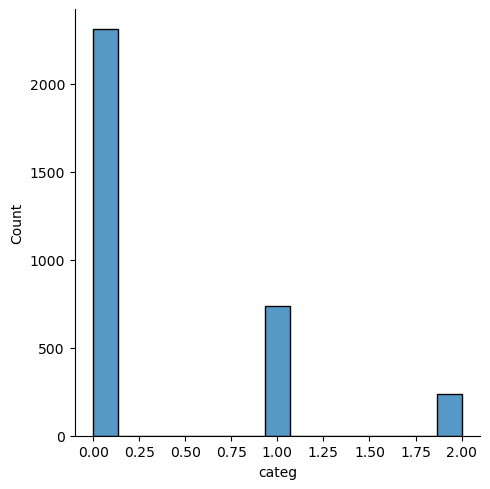

In [15]:
sns.displot(products, x='categ')

Transactions :

In [17]:
Transactions.head(10)

,id_prod,date,Heure,session_id,client_id
0,0_1259,03/01/2021,00:01:08,s_1,c_329
1,0_1390,03/01/2021,00:02:26,s_2,c_664
2,0_1352,03/01/2021,00:02:38,s_3,c_580
3,0_1458,03/01/2021,00:04:55,s_4,c_7912
4,0_1358,03/01/2021,00:05:19,s_5,c_2033
5,0_1073,03/01/2021,00:05:45,s_6,c_4908
6,0_1304,03/01/2021,00:07:04,s_7,c_1609
7,0_279,03/01/2021,00:07:49,s_6,c_4908
8,1_445,03/01/2021,00:09:12,s_8,c_7991
9,1_556,03/01/2021,00:10:20,s_9,c_6171


In [18]:
Transactions.shape

(687534, 5)

In [19]:
Transactions['id_prod'].nunique()

3265

Transformer en série temporelle :

In [21]:
Transactions['date'] = pd.to_datetime(Transactions['date'], dayfirst=True)

In [22]:
serie_temp = Transactions.sort_values('date', ascending=True)

On va commencer par faire une moyenne glissante sur environ un mois - 30 jours

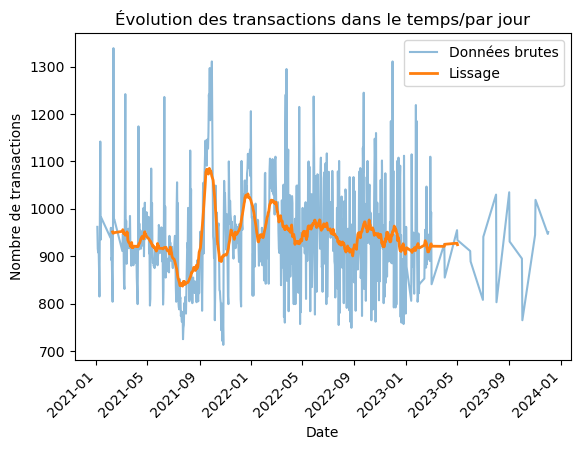

In [24]:
import matplotlib.pyplot as plt

ts = serie_temp.groupby(serie_temp['date']).size()
ts = ts.sort_index()

ts.plot(label="Données brutes", alpha=0.5)

ts_smooth = ts.rolling(window=30, center=True).mean()
ts_smooth.plot(label="Lissage", linewidth=2)

plt.xlabel("Date")
plt.ylabel("Nombre de transactions")
plt.title("Évolution des transactions dans le temps/par jour")

plt.xticks(rotation=45)
plt.legend()
plt.show()

In [25]:
Transaction_client = customers.merge(serie_temp, on='client_id')

In [26]:
Transaction_client.head()

,client_id,sex,birth,id_prod,date,Heure,session_id
0,c_4410,f,1967,0_1054,2021-01-10,13:16:28,s_98432
1,c_4410,f,1967,0_525,2021-01-12,07:36:27,s_127714
2,c_4410,f,1967,2_159,2021-01-12,07:36:26,s_127714
3,c_4410,f,1967,1_621,2021-01-12,07:36:24,s_127714
4,c_4410,f,1967,1_616,2021-01-12,07:31:51,s_127714


In [27]:
Transaction_client_produit = products.merge(Transaction_client, on="id_prod")

In [28]:
Transaction_client_produit.head(10)

,id_prod,price,categ,client_id,sex,birth,date,Heure,session_id
0,0_1421,19.99,0,c_5152,f,1986,2021-04-17,06:09:37,s_21727
1,0_1421,19.99,0,c_2167,f,1960,2021-11-24,00:28:06,s_124134
2,0_1421,19.99,0,c_2167,f,1960,2022-08-24,00:28:06,s_257560
3,0_1421,19.99,0,c_3060,m,1971,2021-06-04,09:35:06,s_16742
4,0_1421,19.99,0,c_3060,m,1971,2022-06-03,09:35:06,s_175117
5,0_1421,19.99,0,c_3060,m,1971,2022-06-11,09:35:06,s_293477
6,0_1421,19.99,0,c_7946,f,1987,2021-10-26,00:06:48,s_110147
7,0_1421,19.99,0,c_1934,f,2004,2021-12-23,00:10:38,s_138491
8,0_1421,19.99,0,c_1199,f,1990,2021-04-27,01:33:12,s_26300
9,0_1421,19.99,0,c_7200,m,1967,2021-08-20,10:53:59,s_78275


Evolution du CA dans le temps :

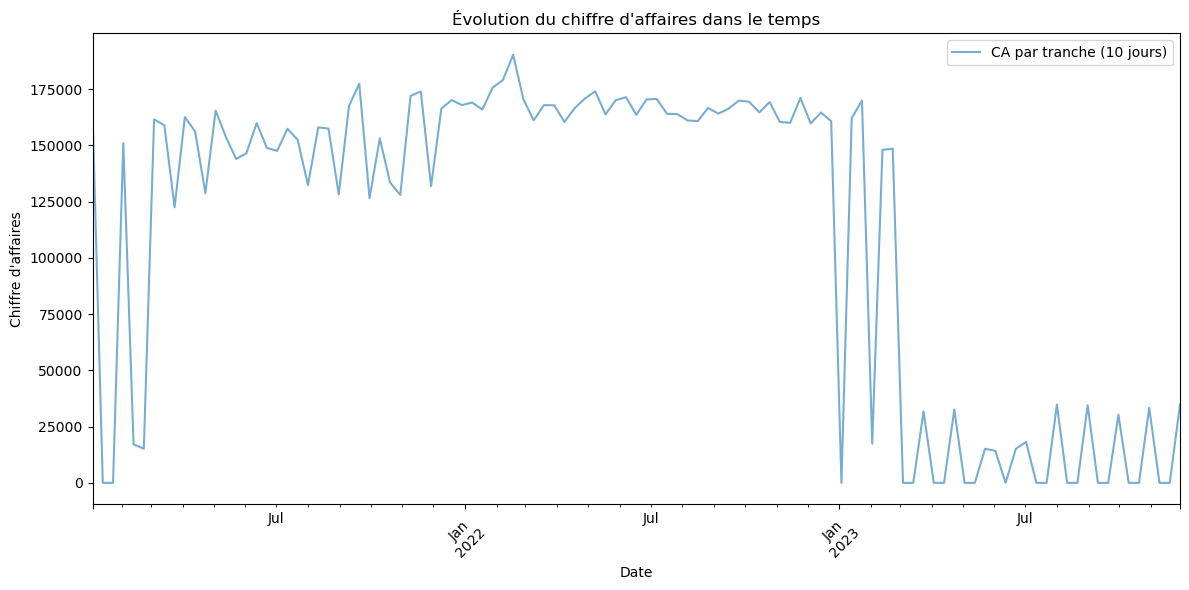

In [30]:
# Définir la date comme index
Transaction_client_produit = Transaction_client_produit.set_index('date').sort_index()

#  Créer les tranches de 10 jours et calculer le CA ---
ts_ca = Transaction_client_produit['price'].resample('10D').sum()

# Affichage
plt.figure(figsize=(12,6))
ts_ca.plot(label="CA par tranche (10 jours)", alpha=0.6)

plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.title("Évolution du chiffre d'affaires dans le temps")
plt.xticks(rotation=45)  # incliner les dates
plt.legend()
plt.tight_layout()
plt.show()

Moyenne mobile :

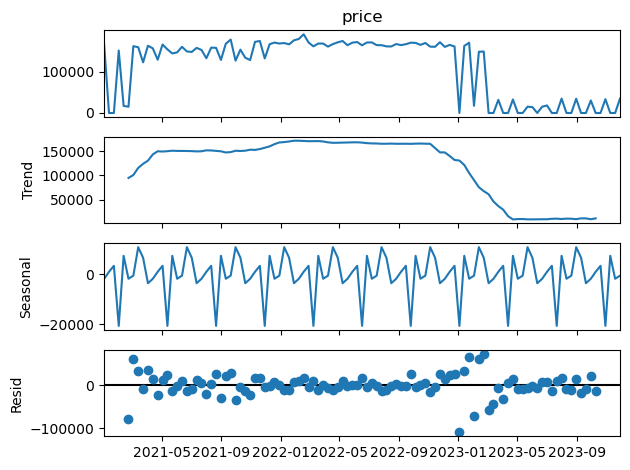

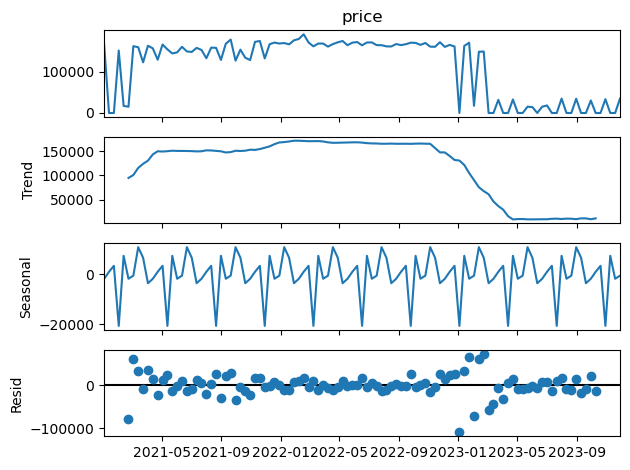

In [32]:
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(ts_ca, model='additive', period=10)

result.plot()

In [33]:
Lorenz = Transaction_client_produit[['client_id', 'price']].groupby('client_id').sum('price').reset_index()

In [34]:
Lorenz.head()

,client_id,price
0,c_1,629.02
1,c_10,1353.60
2,c_100,254.85
3,c_1000,2291.88
4,c_1001,1823.85


In [35]:
Lorenz = Lorenz.sort_values(by='price')
Lorenz.head()

,client_id,price
8151,c_8351,6.31
7918,c_8140,8.30
7889,c_8114,9.98
4044,c_4648,11.20
3855,c_4478,13.36


In [36]:
import numpy as np

Lorenz['pourcent_pop'] = np.arange(1, len(Lorenz)+1) / len(Lorenz)

In [37]:
Lorenz['pourcent_CA'] = Lorenz['price'].cumsum() / Lorenz['price'].sum()

In [38]:
Lorenz.head()

,client_id,price,pourcent_pop,pourcent_CA
8151,c_8351,6.31,0.000116,5.246239e-07
7918,c_8140,8.30,0.000233,1.214700e-06
7889,c_8114,9.98,0.000349,2.044454e-06
4044,c_4648,11.20,0.000465,2.975640e-06
3855,c_4478,13.36,0.000581,4.086413e-06


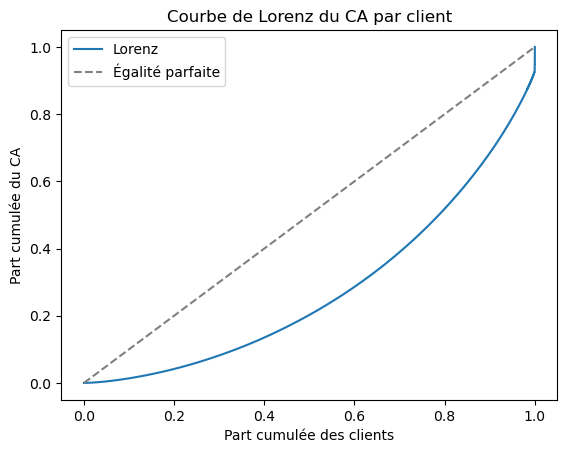

In [39]:
import matplotlib.pyplot as plt

plt.plot(Lorenz['pourcent_pop'], Lorenz['pourcent_CA'], drawstyle='steps-post', label='Lorenz')
plt.plot([0,1],[0,1], '--', color='grey', label='Égalité parfaite')
plt.xlabel("Part cumulée des clients")
plt.ylabel("Part cumulée du CA")
plt.title("Courbe de Lorenz du CA par client")
plt.legend()
plt.show()

Le petit biseau à la fin n'est pas naturel.

<Axes: xlabel='price', ylabel='pourcent_CA'>

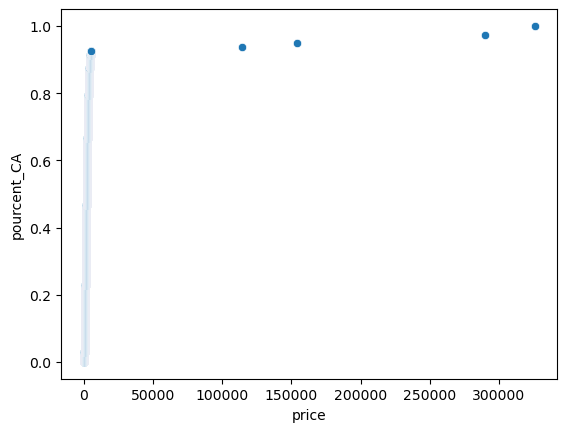

In [41]:
sns.scatterplot(Lorenz, x='price', y='pourcent_CA')

On a donc quatre individus qui ont dépensé plus de 50 000 euros de livres...

In [43]:
sorted_Lorenz = Lorenz.sort_values(by='price', ascending=False)
sorted_Lorenz.head()

,client_id,price,pourcent_pop,pourcent_CA
677,c_1609,326039.89,1.000000,1.000000
4388,c_4958,290227.03,0.999884,0.972892
6337,c_6714,153918.60,0.999767,0.948763
2724,c_3454,114110.57,0.999651,0.935965
634,c_1570,5285.82,0.999535,0.926478


In [44]:
import pandas as pd
total_par_client = Lorenz
clients_plus_50000 = total_par_client[total_par_client['price'] > 50000]
clients_plus_50000 = clients_plus_50000.sort_values(by='price', ascending=False)
top4_clients = clients_plus_50000.head(4)
print(top4_clients)

     client_id      price  pourcent_pop  pourcent_CA
677     c_1609  326039.89      1.000000     1.000000
4388    c_4958  290227.03      0.999884     0.972892
6337    c_6714  153918.60      0.999767     0.948763
2724    c_3454  114110.57      0.999651     0.935965


In [45]:
Lorenz = Lorenz[Lorenz['price'] < 50000].copy()

In [46]:
Lorenz['pourcent_pop'] = np.arange(1, len(Lorenz)+1) / len(Lorenz)
Lorenz['pourcent_CA'] = Lorenz['price'].cumsum() / Lorenz['price'].sum()

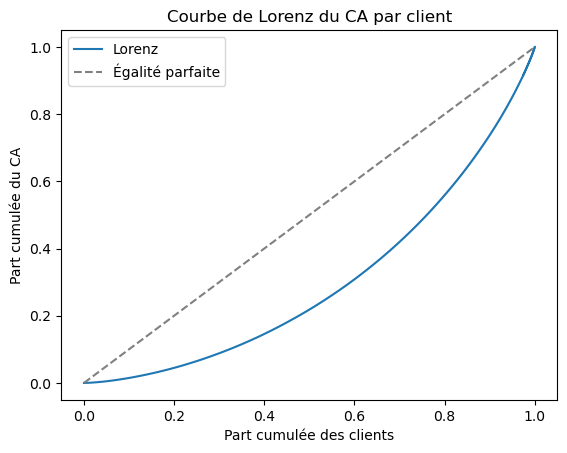

In [47]:
import matplotlib.pyplot as plt

plt.plot(Lorenz['pourcent_pop'], Lorenz['pourcent_CA'], drawstyle='steps-post', label='Lorenz')
plt.plot([0,1],[0,1], '--', color='grey', label='Égalité parfaite')
plt.xlabel("Part cumulée des clients")
plt.ylabel("Part cumulée du CA")
plt.title("Courbe de Lorenz du CA par client")
plt.legend()
plt.show()

Voilà, c'est beaucoup mieux

In [49]:
Transaction_client_produit.head()

,id_prod,price,categ,client_id,sex,birth,Heure,session_id
date,,,,,,,,
2021-01-03,1_644,25.79,1,c_6003,f,1980,23:12:29,s_480
2021-01-03,1_425,16.99,1,c_443,f,1987,01:35:10,s_18
2021-01-03,1_248,10.75,1,c_5525,m,1959,04:34:42,s_93
2021-01-03,0_1381,5.99,0,c_5330,m,1990,19:57:23,s_399
2021-01-03,0_1501,11.99,0,c_4810,f,1988,02:22:16,s_55


In [50]:
# Liste des clients à exclure
clients_a_supprimer = ['c_1609', 'c_4958', 'c_6714', 'c_3454']

# Filtrer le DataFrame pour garder uniquement les autres clients
Transaction_client_produit = Transaction_client_produit[~Transaction_client_produit['client_id'].isin(clients_a_supprimer)]

CA par catégories :

<Axes: xlabel='categ', ylabel='price'>

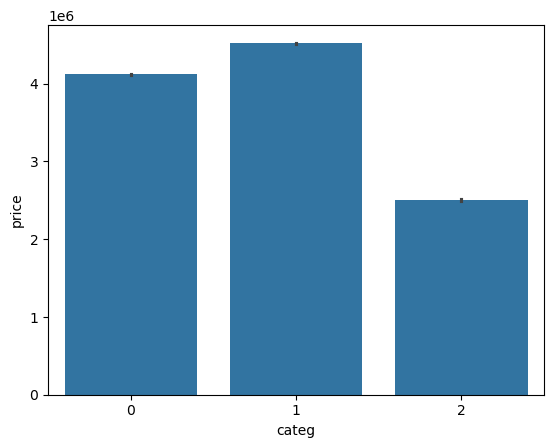

In [52]:
sns.barplot(Transaction_client_produit, x='categ', y='price', estimator='sum')

Clients par mois :

In [54]:
Transaction_client_produit = Transaction_client_produit.reset_index()

Transaction_client_produit['date'] = pd.to_datetime(Transaction_client_produit['date'])

clients_mois = (
    Transaction_client_produit
    .groupby(Transaction_client_produit['date'].dt.to_period('M'))['client_id']
    .nunique()
    .reset_index(name='nb_clients')  
)


In [55]:
clients_mois.head()

,date,nb_clients
0,2021-01,3103
1,2021-02,3146
2,2021-03,5560
3,2021-04,5540
4,2021-05,5548


(array([18628., 18748., 18871., 18993., 19113., 19236., 19358., 19478.,
        19601., 19723.]),
 [Text(18628.0, 0, '2021-01'),
  Text(18748.0, 0, '2021-05'),
  Text(18871.0, 0, '2021-09'),
  Text(18993.0, 0, '2022-01'),
  Text(19113.0, 0, '2022-05'),
  Text(19236.0, 0, '2022-09'),
  Text(19358.0, 0, '2023-01'),
  Text(19478.0, 0, '2023-05'),
  Text(19601.0, 0, '2023-09'),
  Text(19723.0, 0, '2024-01')])

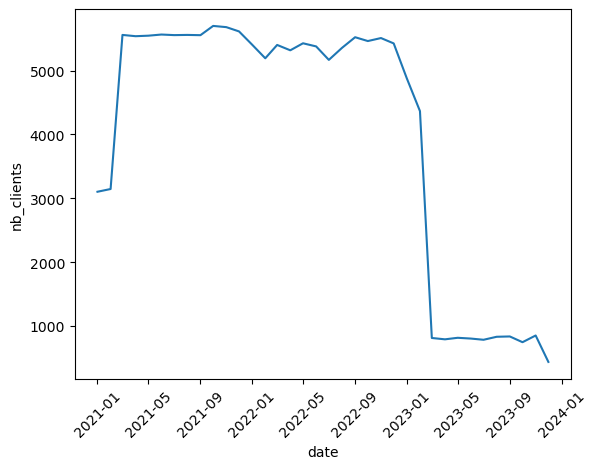

In [56]:
clients_mois['date'] = clients_mois['date'].dt.to_timestamp()

sns.lineplot(
    data=clients_mois,
    x='date',
    y='nb_clients',
)
plt.xticks(rotation=45)  # incline les dates

Nombre de transactions :

In [58]:
Transaction_client_produit.head()

,date,id_prod,price,categ,client_id,sex,birth,Heure,session_id
0,2021-01-03,1_644,25.79,1,c_6003,f,1980,23:12:29,s_480
1,2021-01-03,1_425,16.99,1,c_443,f,1987,01:35:10,s_18
2,2021-01-03,1_248,10.75,1,c_5525,m,1959,04:34:42,s_93
3,2021-01-03,0_1381,5.99,0,c_5330,m,1990,19:57:23,s_399
4,2021-01-03,0_1501,11.99,0,c_4810,f,1988,02:22:16,s_55


In [59]:
transactions_mois = (
    Transaction_client_produit
    .groupby(Transaction_client_produit['date'].dt.to_period('M'))
    .size()
    .reset_index(name='nb_transactions')
)

In [60]:
# Convertir Period -> datetime
transactions_mois['date'] = transactions_mois['date'].dt.to_timestamp()

In [61]:
transactions_mois.head()

,date,nb_transactions
0,2021-01-01,8728
1,2021-02-01,8934
2,2021-03-01,25242
3,2021-04-01,24493
4,2021-05-01,24654


(array([18628., 18748., 18871., 18993., 19113., 19236., 19358., 19478.,
        19601., 19723.]),
 [Text(18628.0, 0, '2021-01'),
  Text(18748.0, 0, '2021-05'),
  Text(18871.0, 0, '2021-09'),
  Text(18993.0, 0, '2022-01'),
  Text(19113.0, 0, '2022-05'),
  Text(19236.0, 0, '2022-09'),
  Text(19358.0, 0, '2023-01'),
  Text(19478.0, 0, '2023-05'),
  Text(19601.0, 0, '2023-09'),
  Text(19723.0, 0, '2024-01')])

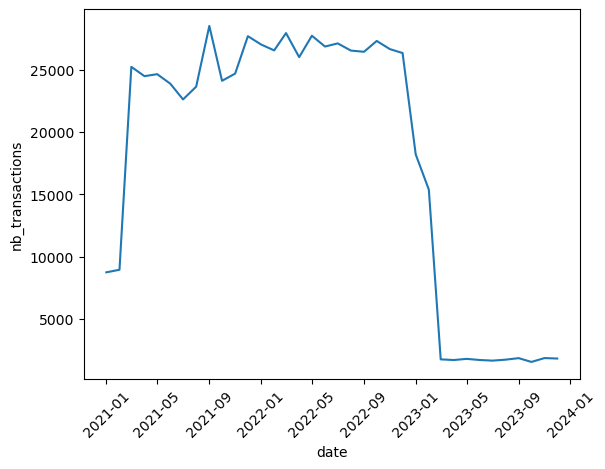

In [62]:
sns.lineplot(
    data=transactions_mois,
    x='date',
    y='nb_transactions')
plt.xticks(rotation=45)  # incline les dates

Nombre de produits vendus :

In [64]:
Transaction_client_produit.head()

,date,id_prod,price,categ,client_id,sex,birth,Heure,session_id
0,2021-01-03,1_644,25.79,1,c_6003,f,1980,23:12:29,s_480
1,2021-01-03,1_425,16.99,1,c_443,f,1987,01:35:10,s_18
2,2021-01-03,1_248,10.75,1,c_5525,m,1959,04:34:42,s_93
3,2021-01-03,0_1381,5.99,0,c_5330,m,1990,19:57:23,s_399
4,2021-01-03,0_1501,11.99,0,c_4810,f,1988,02:22:16,s_55


In [65]:
produits_mois = (
    Transaction_client_produit
    .groupby(Transaction_client_produit['date'].dt.to_period('M'))['id_prod']
    .nunique()
    .reset_index(name='nb_prod')  
)

(array([18628., 18748., 18871., 18993., 19113., 19236., 19358., 19478.,
        19601., 19723.]),
 [Text(18628.0, 0, '2021-01'),
  Text(18748.0, 0, '2021-05'),
  Text(18871.0, 0, '2021-09'),
  Text(18993.0, 0, '2022-01'),
  Text(19113.0, 0, '2022-05'),
  Text(19236.0, 0, '2022-09'),
  Text(19358.0, 0, '2023-01'),
  Text(19478.0, 0, '2023-05'),
  Text(19601.0, 0, '2023-09'),
  Text(19723.0, 0, '2024-01')])

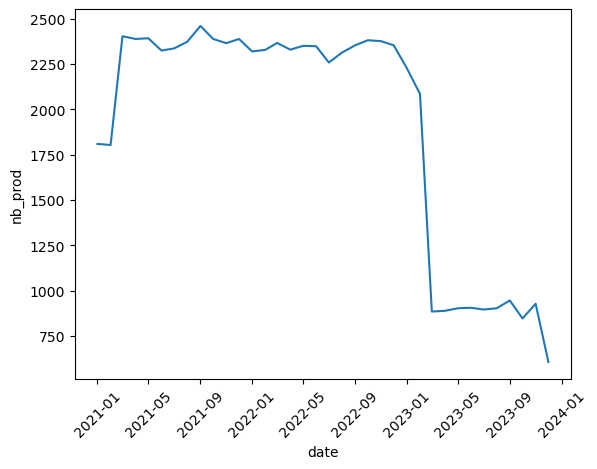

In [66]:
# Convertir Period -> datetime
produits_mois['date'] = produits_mois['date'].dt.to_timestamp()
sns.lineplot(
    data=produits_mois,
    x='date',
    y='nb_prod')
plt.xticks(rotation=45)  # incline les dates

Lien entre le genre d'un client et les catégories de livre achetés :

<Axes: xlabel='sex', ylabel='categ'>

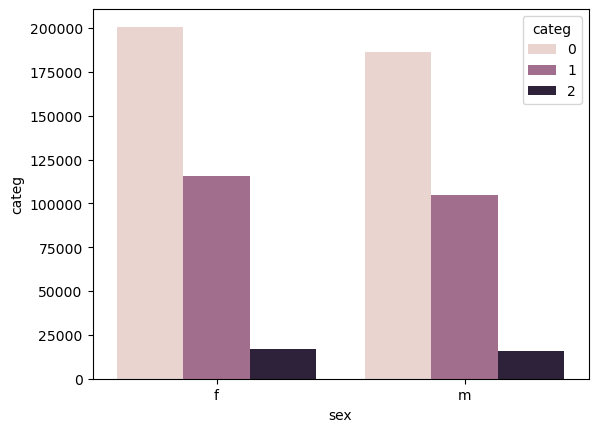

In [68]:
sns.barplot(data=Transaction_client_produit, x="sex", y="categ", hue="categ", estimator=len)

On est sur une distribution sensiblement identique.
On va faire un Khi2 pour le vérifier :

In [70]:
table = pd.crosstab(Transaction_client_produit["sex"],
                    Transaction_client_produit["categ"])
print(table)

categ       0       1      2
sex                         
f      200793  115721  16980
m      186488  104884  15868


In [71]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(table)

print("Chi2 :", chi2)
print("p-value :", p)
print("ddl :", dof)
print("Effectifs attendus :")
print(expected)

Chi2 : 22.66856665178056
p-value : 1.1955928116587024e-05
ddl : 2
Effectifs attendus :
[[201574.89662481 114822.13191434  17096.97146086]
 [185706.10337519 105782.86808566  15751.02853914]]


In [72]:
table = pd.crosstab(Transaction_client_produit["sex"],
                    Transaction_client_produit["categ"])

table_prop = table.div(table.sum(axis=1), axis=0)
print(table_prop)

categ         0         1         2
sex                                
f      0.602089  0.346996  0.050915
m      0.606978  0.341375  0.051647


Le test du χ² rejette l’hypothèse d’indépendance entre le sexe et la catégorie. Toutefois, l’examen des distributions montre que les écarts de proportions sont faibles (environ 0.5 à 1 point de pourcentage). Les différences observées proviennent principalement d’une sous-représentation de la catégorie 1 chez les hommes, compensée par une légère sur-représentation des catégories 0 et 2.

In [74]:
n = table.values.sum()
chi2 = 22.66856665178056

cramers_v = np.sqrt(chi2 / (n * (min(table.shape)-1)))
print(cramers_v)

0.005948029928802536


Le test du χ² rejette l’hypothèse d’indépendance entre le sexe et la catégorie (p < 10⁻³⁴). Cependant, la taille d’effet mesurée par le V de Cramér est très faible (V = 0.005), indiquant que l’association entre les variables est pratiquement négligeable.

Bien maintenant on va regarder le lien entre l'âge des clients et le montant total des achats :

In [77]:
Transaction_client_produit["Age_client"] = 2026 - Transaction_client_produit["birth"]

<Axes: xlabel='Age_client', ylabel='price'>

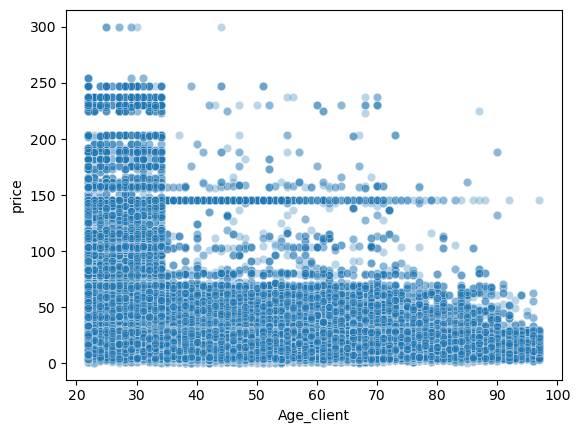

In [78]:
sns.scatterplot(
    data=Transaction_client_produit,
    x="Age_client",
    y="price",
    alpha=0.3  # rend les points translucides si dataset énorme
)

<Axes: xlabel='Age_client', ylabel='price'>

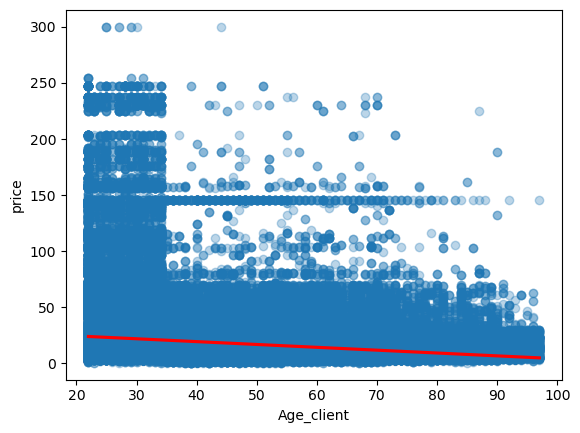

In [79]:
sns.regplot(
    data=Transaction_client_produit,
    x="Age_client",
    y="price",
    scatter_kws={"alpha":0.3},  # points translucides
    line_kws={"color":"red"},   # ligne de tendance
)

In [80]:
from scipy.stats import spearmanr

rho, pval = spearmanr(Transaction_client_produit['Age_client'], Transaction_client_produit['price'])
print("Spearman rho :", rho)
print("p-value :", pval)

Spearman rho : -0.0503822444139796
p-value : 0.0


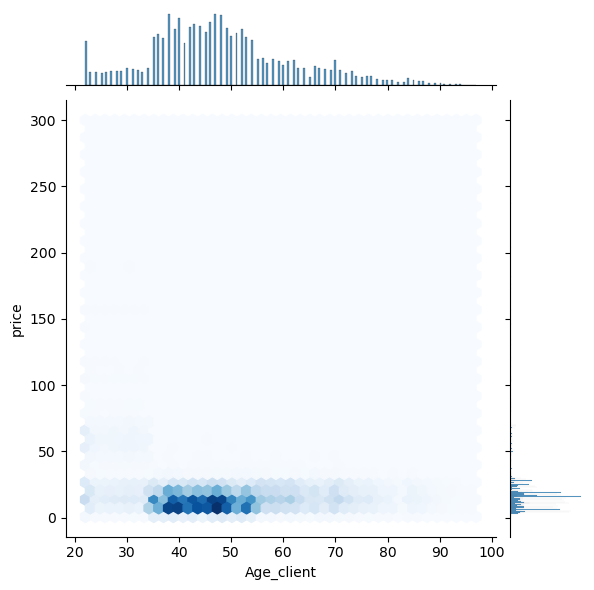

In [81]:
sns.jointplot(
    data=Transaction_client_produit,
    x="Age_client",
    y="price",
    kind="hex",
    gridsize=40,
    cmap="Blues"
)

Conclusion : malgré la visualisation initiale qui pouvait laisser penser que le prix d une transaction pouvait être influencé par l age du client, la corrélation de Spearman montre une très faible corrélation négative entre les deux variables.

Le graphique de densité succintement réalisé permet de mieux visualiser cet effet. Il montre en effet que le L observé sur le premier graphique est en vérité peu significatif. La grande quantité de donnée rend peut pertinent l'analyse par nuage de points. 

Le lien entre l'âge client et fréquence achat

In [84]:
Transaction_client_produit.head(10)

,date,id_prod,price,categ,client_id,sex,birth,Heure,session_id,Age_client
0,2021-01-03,1_644,25.79,1,c_6003,f,1980,23:12:29,s_480,46
1,2021-01-03,1_425,16.99,1,c_443,f,1987,01:35:10,s_18,39
2,2021-01-03,1_248,10.75,1,c_5525,m,1959,04:34:42,s_93,67
3,2021-01-03,0_1381,5.99,0,c_5330,m,1990,19:57:23,s_399,36
4,2021-01-03,0_1501,11.99,0,c_4810,f,1988,02:22:16,s_55,38
5,2021-01-03,0_1140,3.73,0,c_1478,f,1972,01:40:35,s_38,54
6,2021-01-03,2_179,49.99,2,c_4002,f,1994,21:09:42,s_419,32
7,2021-01-03,2_142,105.24,2,c_2494,m,2002,12:32:17,s_239,24
8,2021-01-03,0_1430,16.47,0,c_8062,f,1965,15:40:31,s_327,61
9,2021-01-03,0_2012,3.69,0,c_7532,f,1973,15:06:16,s_304,53


In [85]:
Transaction_client_produit["freq"] = 1

In [86]:
distinct_session_id = Transaction_client_produit.drop_duplicates(['session_id', 'client_id'])


In [87]:
distinct_session_id.shape

(322466, 11)

In [88]:
Transaction_client_produit.shape

(640734, 11)

In [89]:
Transaction_client_produit.head(10)

,date,id_prod,price,categ,client_id,sex,birth,Heure,session_id,Age_client,freq
0,2021-01-03,1_644,25.79,1,c_6003,f,1980,23:12:29,s_480,46,1
1,2021-01-03,1_425,16.99,1,c_443,f,1987,01:35:10,s_18,39,1
2,2021-01-03,1_248,10.75,1,c_5525,m,1959,04:34:42,s_93,67,1
3,2021-01-03,0_1381,5.99,0,c_5330,m,1990,19:57:23,s_399,36,1
4,2021-01-03,0_1501,11.99,0,c_4810,f,1988,02:22:16,s_55,38,1
5,2021-01-03,0_1140,3.73,0,c_1478,f,1972,01:40:35,s_38,54,1
6,2021-01-03,2_179,49.99,2,c_4002,f,1994,21:09:42,s_419,32,1
7,2021-01-03,2_142,105.24,2,c_2494,m,2002,12:32:17,s_239,24,1
8,2021-01-03,0_1430,16.47,0,c_8062,f,1965,15:40:31,s_327,61,1
9,2021-01-03,0_2012,3.69,0,c_7532,f,1973,15:06:16,s_304,53,1


In [90]:
corr_freq_age = distinct_session_id.groupby("client_id").agg({
    "Age_client": "first",  # on garde l’âge du client (toujours le même pour un client)
    "freq": "sum"           # on somme toutes les fréquences
}).reset_index()

In [91]:
corr_freq_age.head()

,client_id,Age_client,freq
0,c_1,71,34
1,c_10,70,34
2,c_100,34,5
3,c_1000,60,94
4,c_1001,44,47


<Axes: xlabel='Age_client', ylabel='freq'>

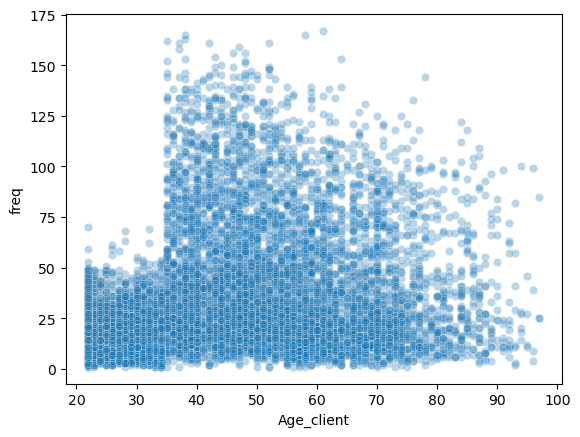

In [92]:
sns.scatterplot(
    data=corr_freq_age,
    x="Age_client",
    y="freq",
    alpha=0.3  # rend les points translucides si dataset énorme
)

In [93]:
from scipy.stats import spearmanr

rho, pval = spearmanr(corr_freq_age['Age_client'], corr_freq_age['freq'])
print("Spearman rho :", rho)
print("p-value :", pval)

Spearman rho : 0.21196373259671872
p-value : 6.629168433162815e-88


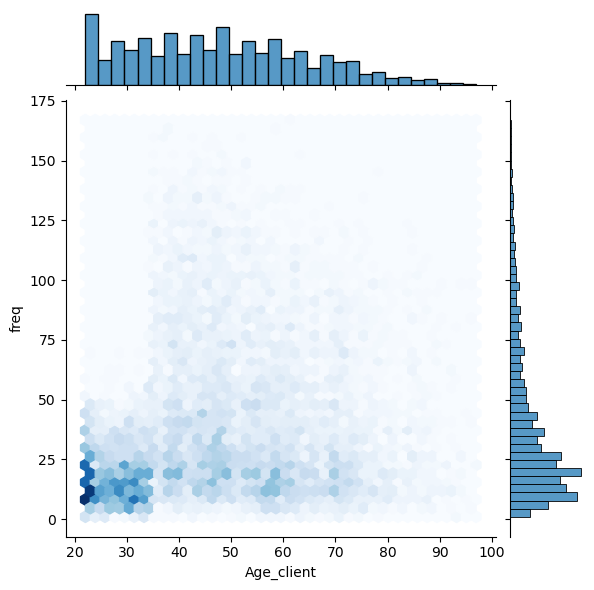

In [94]:
sns.jointplot(
    data=corr_freq_age,
    x="Age_client",
    y="freq",
    kind="hex",
    gridsize=40,
    cmap="Blues"
)

Le lien entre l'âge client et la taille du panier moyen

In [96]:
corr_prix_age = Transaction_client_produit.groupby("client_id").agg({
    "Age_client": "first",  # on garde l’âge du client (toujours le même pour un client)
    "price": "mean"           # on moyennise les prix
}).reset_index()

<Axes: xlabel='Age_client', ylabel='price'>

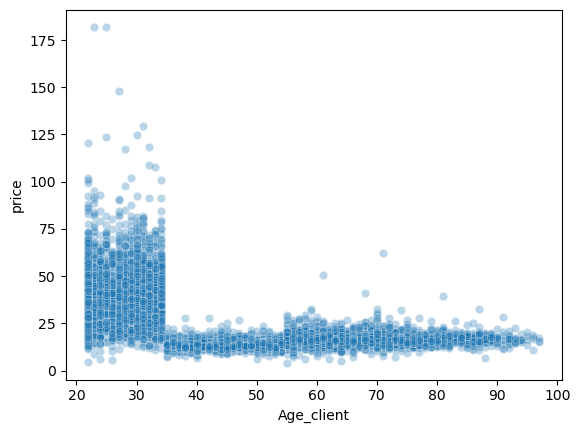

In [97]:
sns.scatterplot(
    data=corr_prix_age,
    x="Age_client",
    y="price",
    alpha=0.3  # rend les points translucides si dataset énorme
)

In [98]:
from scipy.stats import spearmanr

rho, pval = spearmanr(corr_prix_age['Age_client'], corr_prix_age['price'])
print("Spearman rho :", rho)
print("p-value :", pval)

Spearman rho : -0.3258682002720034
p-value : 8.353192440419998e-212


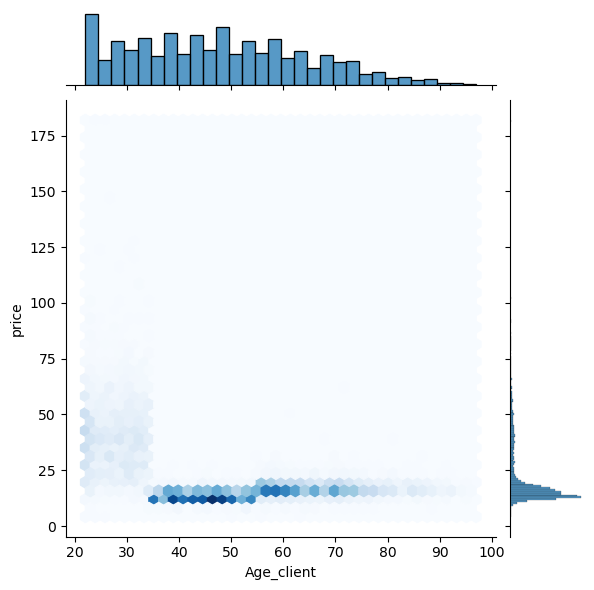

In [99]:
sns.jointplot(
    data=corr_prix_age,
    x="Age_client",
    y="price",
    kind="hex",
    gridsize=40,
    cmap="Blues"
)

Et pour finir le lien entre l'âge client et la catégorie de livre acheté

In [101]:
Transaction_client_produit.head(10)

,date,id_prod,price,categ,client_id,sex,birth,Heure,session_id,Age_client,freq
0,2021-01-03,1_644,25.79,1,c_6003,f,1980,23:12:29,s_480,46,1
1,2021-01-03,1_425,16.99,1,c_443,f,1987,01:35:10,s_18,39,1
2,2021-01-03,1_248,10.75,1,c_5525,m,1959,04:34:42,s_93,67,1
3,2021-01-03,0_1381,5.99,0,c_5330,m,1990,19:57:23,s_399,36,1
4,2021-01-03,0_1501,11.99,0,c_4810,f,1988,02:22:16,s_55,38,1
5,2021-01-03,0_1140,3.73,0,c_1478,f,1972,01:40:35,s_38,54,1
6,2021-01-03,2_179,49.99,2,c_4002,f,1994,21:09:42,s_419,32,1
7,2021-01-03,2_142,105.24,2,c_2494,m,2002,12:32:17,s_239,24,1
8,2021-01-03,0_1430,16.47,0,c_8062,f,1965,15:40:31,s_327,61,1
9,2021-01-03,0_2012,3.69,0,c_7532,f,1973,15:06:16,s_304,53,1


<Axes: xlabel='Age_client', ylabel='Count'>

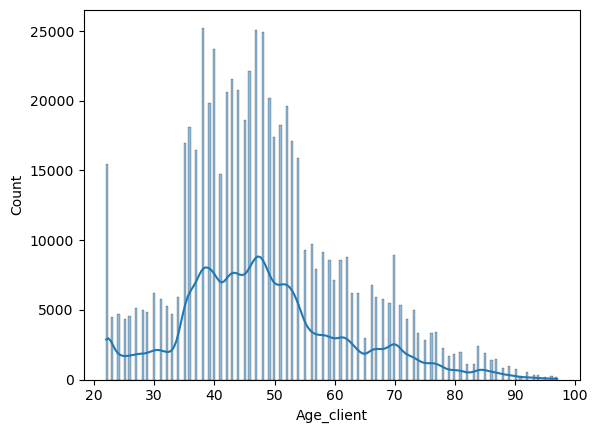

In [102]:
sns.histplot(
    data=Transaction_client_produit,
    x='Age_client',
    kde = True
)

Non normale, on va privilégier Kruskall Wallis à ANOVA :

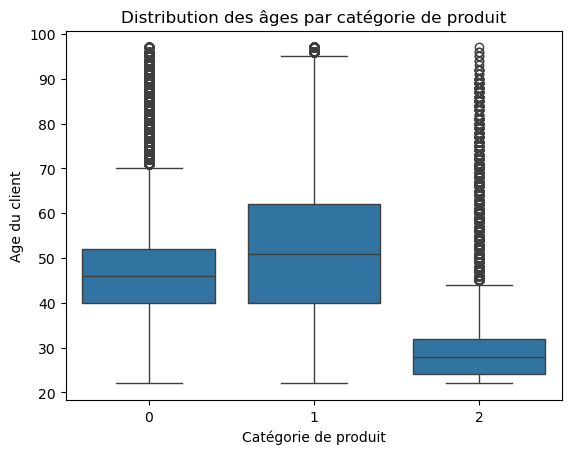

In [104]:
sns.boxplot(
    data=Transaction_client_produit,
    x="categ",
    y="Age_client"
)
plt.xlabel("Catégorie de produit")
plt.ylabel("Age du client")
plt.title("Distribution des âges par catégorie de produit")
plt.show()

In [105]:
from scipy.stats import kruskal

groups = [group["Age_client"].values for name, group in Transaction_client_produit.groupby("categ")]
H, p = kruskal(*groups)
print("H-statistic:", H)
print("p-value:", p)

H-statistic: 71359.73412120914
p-value: 0.0


In [106]:
H = 78458.438
n = len(Transaction_client_produit)
k = Transaction_client_produit['categ'].nunique()
epsilon2 = (H - k + 1) / (n - k)
print("Epsilon² =", epsilon2)

Epsilon² = 0.12244832542829985


In [107]:
import scikit_posthocs as sp

# test post-hoc de Dunn pour toutes les paires de catégories
dunn_results = sp.posthoc_dunn(Transaction_client_produit, val_col='Age_client', group_col='categ', p_adjust='bonferroni')
print(dunn_results)

     0    1    2
0  1.0  0.0  0.0
1  0.0  1.0  0.0
2  0.0  0.0  1.0


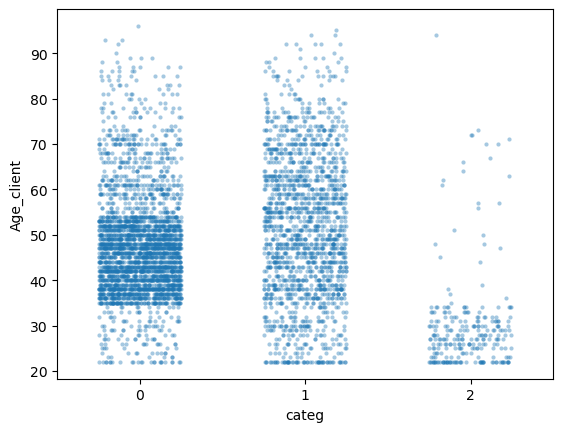

In [108]:
sample = Transaction_client_produit.sample(n=5000, random_state=42)

sns.stripplot(
    data=sample,
    x="categ",
    y="Age_client",
    size=3,
    alpha=0.4,
    jitter=0.25
)

plt.show()

Analyse Top/Flop :

In [110]:
Transaction_client_produit.head()

,date,id_prod,price,categ,client_id,sex,birth,Heure,session_id,Age_client,freq
0,2021-01-03,1_644,25.79,1,c_6003,f,1980,23:12:29,s_480,46,1
1,2021-01-03,1_425,16.99,1,c_443,f,1987,01:35:10,s_18,39,1
2,2021-01-03,1_248,10.75,1,c_5525,m,1959,04:34:42,s_93,67,1
3,2021-01-03,0_1381,5.99,0,c_5330,m,1990,19:57:23,s_399,36,1
4,2021-01-03,0_1501,11.99,0,c_4810,f,1988,02:22:16,s_55,38,1


In [111]:
Top_Flop = Transaction_client_produit.groupby(['id_prod', 'categ'])[['freq', 'price']].sum()

In [112]:
sorted_Top_Flop = Top_Flop.sort_values(by='freq').reset_index()
sorted_Top_Flop.head(10)

,id_prod,categ,freq,price
0,0_833,0,1,2.99
1,2_81,2,1,86.99
2,0_807,0,1,1.99
3,0_1151,0,1,2.99
4,0_1284,0,1,1.38
5,2_98,2,1,149.74
6,0_1728,0,1,2.27
7,0_1539,0,1,0.99
8,0_1726,0,1,1.57
9,0_541,0,1,1.99


<Axes: xlabel='id_prod', ylabel='price'>

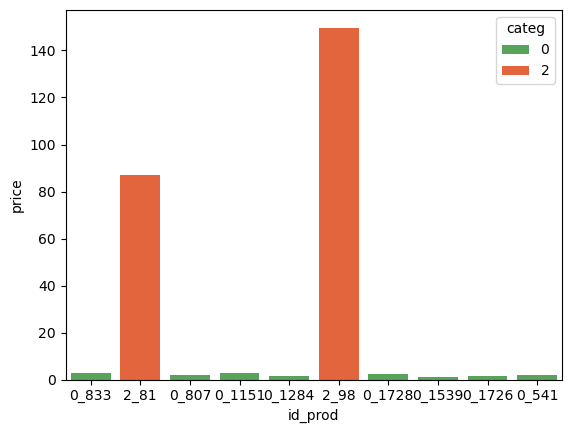

In [113]:
palette = {
    0: "#4CAF50",   
    1: "#2196F3",   
    2: "#FF5722"    
}

sns.barplot(
    data=sorted_Top_Flop.head(10),
    x='id_prod',
    y='price',
    hue='categ',
    palette=palette
)

In [114]:
sorted_Top_Flop = Top_Flop.sort_values(by='freq', ascending = False).reset_index()
sorted_Top_Flop.head(10)

,id_prod,categ,freq,price
0,1_369,1,2205,52897.95
1,1_417,1,2123,44561.77
2,1_414,1,2114,50376.62
3,1_498,1,2042,47721.54
4,1_425,1,2026,34421.74
5,1_413,1,1935,34810.65
6,1_412,1,1915,31884.75
7,1_407,1,1883,30109.17
8,1_396,1,1875,34875.00
9,1_403,1,1874,33713.26


<Axes: xlabel='id_prod', ylabel='price'>

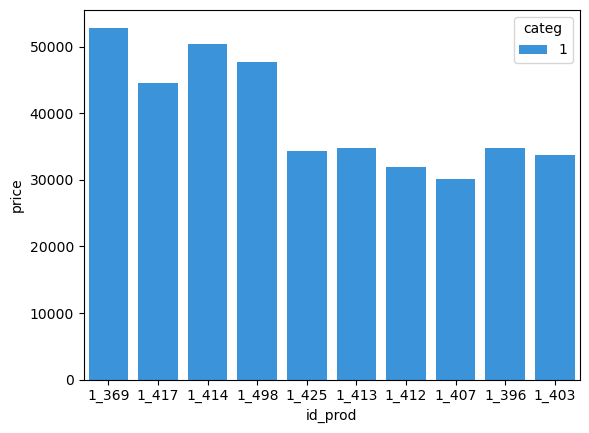

In [115]:
palette = {
    0: "#4CAF50",   
    1: "#2196F3",   
    2: "#FF5722"    
}

sns.barplot(
    data=sorted_Top_Flop.head(10),
    x='id_prod',
    y='price',
    hue='categ',
    palette=palette
)

In [116]:
sorted_Top_Flop = Top_Flop.sort_values(by='price').reset_index()
sorted_Top_Flop.head(10)

,id_prod,categ,freq,price
0,0_1539,0,1,0.99
1,0_1191,0,1,0.99
2,0_1284,0,1,1.38
3,0_1726,0,1,1.57
4,0_1653,0,2,1.98
5,0_807,0,1,1.99
6,0_541,0,1,1.99
7,0_1601,0,1,1.99
8,0_1871,0,1,1.99
9,0_1728,0,1,2.27


<Axes: xlabel='id_prod', ylabel='price'>

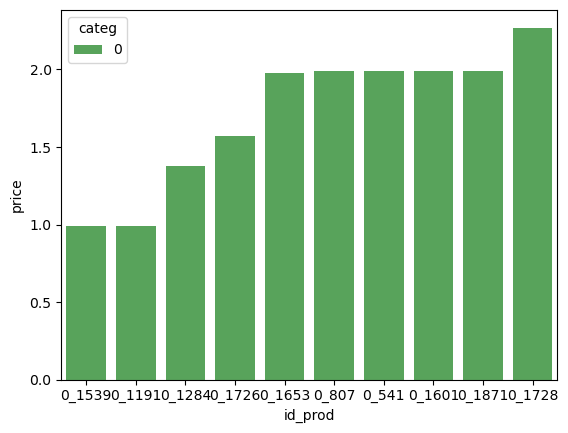

In [117]:
palette = {
    0: "#4CAF50",   
    1: "#2196F3",   
    2: "#FF5722"    
}

sns.barplot(
    data=sorted_Top_Flop.head(10),
    x='id_prod',
    y='price',
    hue='categ',
    palette=palette
)

In [118]:
sorted_Top_Flop = Top_Flop.sort_values(by='price', ascending = False).reset_index()
sorted_Top_Flop.head(10)

,id_prod,categ,freq,price
0,2_159,2,624,91097.76
1,2_135,2,920,63470.80
2,2_112,2,870,58785.90
3,2_102,2,941,55650.74
4,1_369,1,2205,52897.95
5,1_395,1,1800,52182.00
6,2_209,2,725,50742.75
7,1_414,1,2114,50376.62
8,1_383,1,1716,49746.84
9,2_166,2,210,48308.40


<Axes: xlabel='id_prod', ylabel='price'>

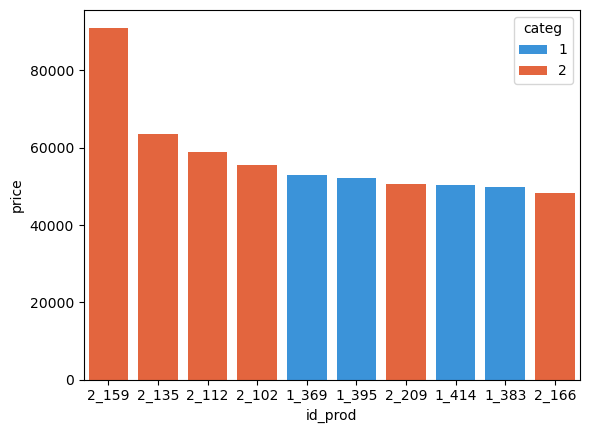

In [119]:
palette = {
    0: "#4CAF50",   
    1: "#2196F3",   
    2: "#FF5722"    
}

sns.barplot(
    data=sorted_Top_Flop.head(10),
    x='id_prod',
    y='price',
    hue='categ',
    palette=palette
)

In [120]:
Transaction_client_produit.head(10)

,date,id_prod,price,categ,client_id,sex,birth,Heure,session_id,Age_client,freq
0,2021-01-03,1_644,25.79,1,c_6003,f,1980,23:12:29,s_480,46,1
1,2021-01-03,1_425,16.99,1,c_443,f,1987,01:35:10,s_18,39,1
2,2021-01-03,1_248,10.75,1,c_5525,m,1959,04:34:42,s_93,67,1
3,2021-01-03,0_1381,5.99,0,c_5330,m,1990,19:57:23,s_399,36,1
4,2021-01-03,0_1501,11.99,0,c_4810,f,1988,02:22:16,s_55,38,1
5,2021-01-03,0_1140,3.73,0,c_1478,f,1972,01:40:35,s_38,54,1
6,2021-01-03,2_179,49.99,2,c_4002,f,1994,21:09:42,s_419,32,1
7,2021-01-03,2_142,105.24,2,c_2494,m,2002,12:32:17,s_239,24,1
8,2021-01-03,0_1430,16.47,0,c_8062,f,1965,15:40:31,s_327,61,1
9,2021-01-03,0_2012,3.69,0,c_7532,f,1973,15:06:16,s_304,53,1
